# M4 · Tráfico en las rondas y días de incidencia de Rodalies
**Datos:** tiempos de recorrido (s) de 78 itinerarios de Barcelona (Ajuntament), una lectura cada 5–10 min,
ene–mar 2023 y nov 2023 – ago 2025. No miden volumen de coches, sino **congestión**.
Se reutilizan el calendario (`m2_cal`) y los tipos de día (`m2_tipos_dia`) de M2.

**Hipótesis**
- **H4:** los días de caos de Rodalies hay más congestión en las rondas (paso al coche).
- **H5:** en la avería de la R1 (13/05/2024) la congestión sube más en el acceso norte (Nus de la Trinitat).
- **Validación:** en los días limpios, más viajes a BCN (Telefónica) ⇒ más congestión.

## 1. Configuración

In [22]:
import warnings
warnings.filterwarnings("ignore", message=".*dayofweek is deprecated.*")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RAW_TR  = ROOT / "data" / "raw" / "trafic"
OUT     = ROOT / "data" / "processed" / "rmove"
F_ITIN  = RAW_TR / "transit_relacio_tram_per_itinerari.csv"
F_CACHE = OUT / "m4_trafico_5min.parquet"
F_M2    = ROOT / "data" / "processed" / "telefonica" / "M2.parquet"

DIAS_CAOS = {                       # mismos días que M2/M3
    "2024-05-13": "Avería Montcada (R1, R3, R4, R7)",
    "2025-03-17": "Huelga 17/03",
    "2025-03-26": "Huelga 26/03",
    "2025-04-01": "Huelga 01/04",
}
DIAS_EXTRA = {"2024-05-14": "Montcada, día 2"}     # caso secundario (no entra en la media)
TODOS_DIAS = {**DIAS_CAOS, **DIAS_EXTRA}
FRANJAS = {"manana": (7, 10), "tarde": (17, 20)}   # [inicio, fin) en horas
H_LIBRE = (2, 5)                    # horas de flujo libre (referencia del índice)
K_REF = 8                           # días limpios más cercanos del mismo día de la semana
RONDAS = list(range(65, 77))
print(ROOT, "| ficheros de tráfico:", len(list(RAW_TR.glob("trafico_barcelona_*.csv"))))

c:\Users\marti\R-MOVE | ficheros de tráfico: 25


## 2. Carga de los datos de tráfico
Se lee todo como texto y se convierte a número (un mes tiene valores no numéricos). `tempsActual = 0` = sin dato. El resultado se guarda en caché.

In [23]:
def a_num(s):
    return pd.to_numeric(s.astype(str).str.strip().str.replace(",", ".", regex=False), errors="coerce")

if F_CACHE.exists():
    tr = pd.read_parquet(F_CACHE)
else:
    trozos = []
    for f in sorted(RAW_TR.glob("trafico_barcelona_*.csv")):
        d = pd.read_csv(f, usecols=["idTram", "data", "tempsActual"], dtype=str)
        d["idTram"], d["tempsActual"] = a_num(d.idTram), a_num(d.tempsActual)
        dig = d.data.astype(str).str.replace(r"\.0$", "", regex=True).str.replace(r"\D", "", regex=True).str[:14]
        d["ts"] = pd.to_datetime(dig, format="%Y%m%d%H%M%S", errors="coerce")
        n0 = len(d)
        d = d.dropna(subset=["idTram", "tempsActual", "ts"])
        d = d[d.tempsActual > 0]
        trozos.append(d[["idTram", "ts", "tempsActual"]])
        print(f"{f.name}: {n0} filas → {len(d)} válidas")
    tr = pd.concat(trozos, ignore_index=True).rename(columns={"idTram": "itin", "tempsActual": "t"})
    tr["itin"] = tr.itin.astype("int16"); tr["t"] = tr.t.round().astype("int32")
    tr.to_parquet(F_CACHE)
tr["fecha"] = tr.ts.dt.normalize()
tr["h"] = tr.ts.dt.hour
print(tr.shape, tr.ts.min(), "→", tr.ts.max())

(5213302, 5) 2023-01-01 00:00:54 → 2025-08-31 23:52:03


## 3. Calidad de los itinerarios
Solo las **rondas** (Dalt 65–70 y Litoral 71–76) tienen variación real (p95/mediana entre 1,1 y 4,4). Las calles del interior tienen tiempos casi constantes y varias no tienen datos. El análisis se hace con las 12 rondas, que son además la entrada en coche desde el área metropolitana.

In [24]:
rel = pd.read_csv(F_ITIN)
itin = rel[rel.Tram == 0].set_index("Itinerari")["Descripció"].rename("nombre").to_frame()
lab = tr[tr.ts.dt.day_of_week < 5]
q = lab.groupby("itin").t.quantile([0.5, 0.95]).unstack()
itin["t_mediana_s"] = q[0.5]
itin["p95_p50"] = (q[0.95] / q[0.5]).round(2)
itin["cobertura"] = (tr.groupby("itin").size() / tr.groupby("fecha").ts.nunique().sum()).round(2)
itin["sensible"] = (itin.cobertura >= 0.5) & (itin.p95_p50 >= 1.10) & itin.index.isin(RONDAS)

GRUPOS = {"Ronda de Dalt": [65, 66, 67, 68, 69, 70], "Ronda Litoral": [71, 72, 73, 74, 75, 76]}
CORREDOR = {"Nord (Nus de la Trinitat)": [67, 68, 71, 76], "Sud/oest (Llobregat)": [65, 70, 73, 74]}
itin["grupo"] = itin.index.map({i: g for g, l in GRUPOS.items() for i in l})
itin["corredor"] = itin.index.map({i: c for c, l in CORREDOR.items() for i in l})
display(itin[itin.sensible])

,nombre,t_mediana_s,p95_p50,cobertura,sensible,grupo,corredor
Itinerari,,,,,,,
65,Ronda de Dalt de Diagonal a Sant Gervasi,142.0,4.41,0.98,True,Ronda de Dalt,Sud/oest (Llobregat)
66,Ronda de Dalt de Sant Gervasi a Av. Estatut,119.0,3.19,0.97,True,Ronda de Dalt,NaN
67,Ronda de Dalt d'Av. Estatut a Nus de la Trinitat,228.0,1.94,0.98,True,Ronda de Dalt,Nord (Nus de la Trinitat)
68,Ronda de Dalt de Nus de la Trinitat a Av. Estatut,128.0,3.72,0.97,True,Ronda de Dalt,Nord (Nus de la Trinitat)
69,Ronda de Dalt d'Av. Estatut a Sant Gervasi,139.0,2.14,0.96,True,Ronda de Dalt,NaN
70,Ronda de Dalt de Sant Gervasi a Diagonal,137.0,1.63,0.98,True,Ronda de Dalt,Sud/oest (Llobregat)
71,Ronda Litoral de Nus de la Trinitat a Rambla d...,104.0,1.23,0.99,True,Ronda Litoral,Nord (Nus de la Trinitat)
72,Ronda Litoral de Rambla de Prim a Josep Carner,201.0,3.14,0.91,True,Ronda Litoral,NaN
73,Ronda Litoral de Josep Carner a Estació de Can...,115.0,1.10,0.99,True,Ronda Litoral,Sud/oest (Llobregat)


## 4. Indicador diario
Por tramo y día: tiempo medio en la punta de la mañana (7–10 h, llegada a BCN) y de la tarde (17–20 h, vuelta). **Índice de congestión** = tiempo / tiempo de madrugada (2–5 h): 1 = flujo libre. Solo cuentan las franjas con ≥ 50 % de las lecturas de un día típico del mismo mes.

In [25]:
libre = (tr[tr.h.between(H_LIBRE[0], H_LIBRE[1] - 1) & (tr.ts.dt.day_of_week < 5)]
         .groupby("itin").t.median().rename("t_libre"))
filas = []
for nombre, (h0, h1) in FRANJAS.items():
    g = (tr[(tr.h >= h0) & (tr.h < h1)].groupby(["itin", "fecha"])
         .agg(t=("t", "mean"), n=("t", "size")).reset_index())
    g["franja"] = nombre
    filas.append(g)
dia = pd.concat(filas)
dia["mes"] = dia.fecha.dt.to_period("M")
dia["n_tipico"] = dia.groupby(["itin", "franja", "mes"]).n.transform("median")
dia = dia[dia.n >= 0.5 * dia.n_tipico].drop(columns=["mes", "n_tipico"])
dia = dia.merge(libre, on="itin")
dia["indice"] = dia.t / dia.t_libre
dia["y"] = np.log(dia.t)
dia = dia[dia.itin.isin(itin.index[itin.sensible])]

cal = pd.read_parquet(OUT / "m2_cal.parquet")
if "fecha" in cal.columns: cal = cal.set_index("fecha")
cal.index = pd.to_datetime(cal.index)
dia = dia.merge(cal[["limpio", "dow", "mal_tiempo"]], left_on="fecha", right_index=True, how="left")
dia["limpio"] = dia.limpio.fillna(False).astype(bool)
dia["mal_tiempo"] = dia.mal_tiempo.fillna(False).astype(bool)
dia["grupo"] = dia.itin.map(itin.grupo)
print(dia.shape)

# ¿Qué días de caos tienen datos suficientes?
cob = dia[dia.fecha.isin(pd.to_datetime(list(TODOS_DIAS)))].groupby(["fecha", "franja"]).itin.nunique().unstack()
cob.index = [TODOS_DIAS[d.strftime("%Y-%m-%d")] for d in cob.index]
print("Nº de tramos (de 12) con datos válidos en cada día de caos:"); display(cob)

(16260, 12)
Nº de tramos (de 12) con datos válidos en cada día de caos:


franja,manana,tarde
"Avería Montcada (R1, R3, R4, R7)",12,12
"Montcada, día 2",12,12
Huelga 17/03,12,12
Huelga 26/03,12,12
Huelga 01/04,12,12


## 5. Validación del indicador
Si funciona: fin de semana ≈ 1, laborables > 1 y más congestión los días de mal tiempo.

In [26]:
lab = dia[dia.dow < 5]
display(pd.DataFrame({
    "Laborable limpio": lab[lab.limpio].groupby(["grupo", "franja"]).indice.median(),
    "Laborable con mal tiempo": lab[lab.mal_tiempo].groupby(["grupo", "franja"]).indice.median(),
    "Fin de semana": dia[dia.dow >= 5].groupby(["grupo", "franja"]).indice.median(),
}).round(2))

Laborable limpio  Laborable con mal tiempo  \
grupo         franja                                               
Ronda Litoral manana              1.35                      1.26   
              tarde               1.28                      1.27   
Ronda de Dalt manana              1.59                      1.55   
              tarde               1.40                      1.45   

                      Fin de semana  
grupo         franja                 
Ronda Litoral manana           1.00  
              tarde            1.11  
Ronda de Dalt manana           1.00  
              tarde            1.10

**Resultado.** El indicador distingue claramente los laborables (1,35–1,59) de los fines de semana (1,00).
Los días de mal tiempo no salen más congestionados (1,26–1,55): posiblemente la lluvia también reduce los desplazamientos.

## 6. Efecto en los días de caos (H4)
Efecto = tiempo del día de caos / mediana de los 8 días limpios más cercanos del mismo día de la semana − 1.
El p-valor sale de repetir el cálculo con **todos los días limpios** (placebo): qué proporción de días normales
da un efecto igual o mayor. Efecto > 0 = más congestión.

In [27]:
def efecto_dia(df, d):
    ref = df[df.limpio & (df.dow == d.day_of_week) & (df.fecha != d)].copy()
    ref["dist"] = (ref.fecha - d).abs()
    ref = ref.sort_values("dist").groupby(["itin", "franja"]).head(K_REF)
    base = ref.groupby(["itin", "franja"]).y.median()
    hoy = df[df.fecha == d].set_index(["itin", "franja"]).y
    return (hoy - base).dropna()

def resumen(dias, col="grupo"):
    filas = []
    for d in dias:
        e = efecto_dia(dia, d).rename("e").reset_index()
        e["g"] = e.itin.map(itin[col])
        for (g, fr), v in e.dropna(subset=["g"]).groupby(["g", "franja"]).e:
            filas.append({"fecha": d, "grupo": g, "franja": fr, "ef": v.mean(), "n_tramos": len(v)})
    return pd.DataFrame(filas)

limpios = sorted(dia.loc[dia.limpio & (dia.dow < 5), "fecha"].unique())
plac = resumen(limpios)
real = resumen([d for d in pd.to_datetime(list(TODOS_DIAS)) if d in set(dia.fecha)])
real["efecto_%"] = (np.expm1(real.ef) * 100).round(1)
real["p_placebo"] = real.apply(lambda r: (plac[(plac.grupo == r.grupo) & (plac.franja == r.franja)].ef.abs()
                                          >= abs(r.ef)).mean(), axis=1).round(3)
real["dia"] = real.fecha.dt.strftime("%Y-%m-%d").map(TODOS_DIAS)
print("Efecto (%)"); display(real.pivot_table(index=["dia", "franja"], columns="grupo", values="efecto_%"))
print("p placebo"); display(real.pivot_table(index=["dia", "franja"], columns="grupo", values="p_placebo"))
print("Rango de un día normal (percentiles 2,5–97,5 %, en %)")
display(plac.groupby(["grupo", "franja"]).ef.quantile([0.025, 0.975]).unstack().pipe(lambda x: (np.expm1(x) * 100).round(1)))

Efecto (%)


grupo                                    Ronda Litoral  Ronda de Dalt
dia                              franja                              
Avería Montcada (R1, R3, R4, R7) manana           -1.4          -12.9
                                 tarde            28.3           17.9
Huelga 01/04                     manana           -3.0            1.9
                                 tarde            -0.4            5.0
Huelga 17/03                     manana           -1.7            1.4
                                 tarde            17.8           16.2
Huelga 26/03                     manana           -0.4           -5.8
                                 tarde            -0.8           -0.6
Montcada, día 2                  manana           28.2           29.7
                                 tarde             0.2           13.7

p placebo


grupo                                    Ronda Litoral  Ronda de Dalt
dia                              franja                              
Avería Montcada (R1, R3, R4, R7) manana          0.874          0.229
                                 tarde           0.036          0.189
Huelga 01/04                     manana          0.748          0.869
                                 tarde           0.973          0.694
Huelga 17/03                     manana          0.860          0.916
                                 tarde           0.135          0.212
Huelga 26/03                     manana          0.972          0.570
                                 tarde           0.950          0.959
Montcada, día 2                  manana          0.014          0.065
                                 tarde           0.986          0.270

Rango de un día normal (percentiles 2,5–97,5 %, en %)


0.025  0.975
grupo         franja              
Ronda Litoral manana  -11.6   22.3
              tarde   -13.1   30.2
Ronda de Dalt manana  -17.9   40.4
              tarde   -18.4   38.2

**Prueba conjunta:** media de los 4 días de caos principales frente a la media de 4 días limpios al azar (10.000 veces). Evita el problema de hacer muchas pruebas sueltas.

In [28]:
principales = pd.to_datetime(list(DIAS_CAOS))
rng = np.random.default_rng(0)
filas = []
for (g, fr), sub in real[real.fecha.isin(principales)].groupby(["grupo", "franja"]):
    pl = plac[(plac.grupo == g) & (plac.franja == fr)].ef.values
    sims = rng.choice(pl, (10_000, len(sub))).mean(axis=1)
    m = sub.ef.mean()
    filas.append({"grupo": g, "franja": fr, "dias": len(sub), "efecto_medio_%": round(np.expm1(m) * 100, 1),
                  "p_placebo": round((np.abs(sims) >= abs(m)).mean(), 3)})
display(pd.DataFrame(filas))

,grupo,franja,dias,efecto_medio_%,p_placebo
0,Ronda Litoral,manana,4,-1.6,0.727
1,Ronda Litoral,tarde,4,10.5,0.129
2,Ronda de Dalt,manana,4,-4.0,0.541
3,Ronda de Dalt,tarde,4,9.3,0.208


**Resultado H4.** En la punta de la mañana del día de caos no hay más congestión: todos los efectos entre −13 % y +2 %,
y la prueba conjunta da −1,6 % (Litoral, p = 0,73) y −4,0 % (Dalt, p = 0,54). Por la tarde hay un aumento medio del
+9–10 %, no significativo (p = 0,13–0,21). Las huelgas anunciadas del 26/03 y del 01/04 no muestran ningún efecto.
La excepción es el **14/05/2024** (día siguiente a la avería de Montcada): +28–30 % por la mañana (p = 0,014 / 0,065).
Nota: el 01/04/2025 no tiene datos antes de las ~8:30.

## 7. Detalle por tramo y perfiles horarios
Gráfico: tiempo medio por tramo cada 15 min. Gris = mediana de los días limpios de referencia y franja = rango normal (10–90 %). Si la línea roja sale de la franja, el día es anómalo.

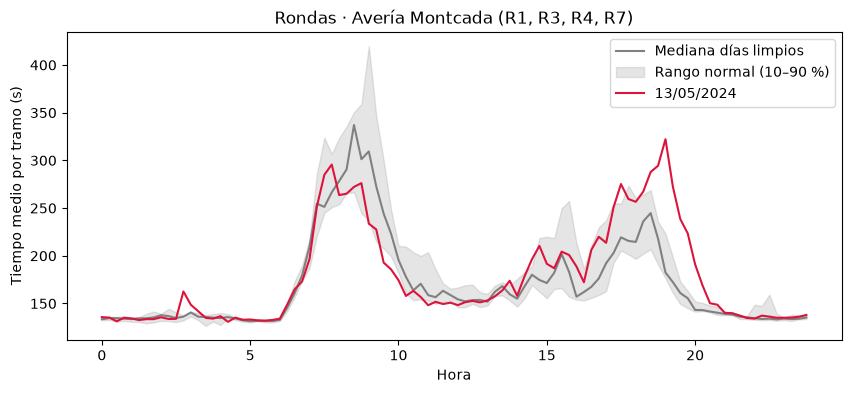

2024-05-13 · Avería Montcada (R1, R3, R4, R7)


franja                                                                             manana  \
corredor                  itin nombre                                                       
-                         66   Ronda de Dalt de Sant Gervasi a Av. Estatut            1.7   
                          69   Ronda de Dalt d'Av. Estatut a Sant Gervasi           -33.4   
                          72   Ronda Litoral de Rambla de Prim a Josep Carner        -5.7   
                          75   Ronda Litoral de Josep Carner a Rambla de Prim        -0.2   
Nord (Nus de la Trinitat) 67   Ronda de Dalt d'Av. Estatut a Nus de la Trinitat      15.0   
                          68   Ronda de Dalt de Nus de la Trinitat a Av. Estatut    -22.2   
                          71   Ronda Litoral de Nus de la Trinitat a Rambla de...   -13.3   
                          76   Ronda Litoral de Rambla de Prim a Nus de la Tri...   -19.5   
Sud/oest (Llobregat)      65   Ronda de Dalt de Diagonal a Sant Gervasi             -15.4   
                          70   Ronda de Dalt de Sant Gervasi a Diagonal             -14.7   
                          73   Ronda Litoral de Josep Carner a Estació de Can ...     0.9   
                          74   Ronda Litoral d'Estació de Can Tunis a Josep Ca...    38.6   

franja                                                                             tarde  
corredor                  itin nombre                                                     
-                         66   Ronda de Dalt de Sant Gervasi a Av. Estatut          41.7  
                          69   Ronda de Dalt d'Av. Estatut a Sant Gervasi            2.6  
                          72   Ronda Litoral de Rambla de Prim a Josep Carner       69.8  
                          75   Ronda Litoral de Josep Carner a Rambla de Prim       -5.8  
Nord (Nus de la Trinitat) 67   Ronda de Dalt d'Av. Estatut a Nus de la Trinitat     15.4  
                          68   Ronda de Dalt de Nus de la Trinitat a Av. Estatut    -0.5  
                          71   Ronda Litoral de Nus de la Trinitat a Rambla de...    0.6  
                          76   Ronda Litoral de Rambla de Prim a Nus de la Tri...    1.4  
Sud/oest (Llobregat)      65   Ronda de Dalt de Diagonal a Sant Gervasi             58.1  
                          70   Ronda de Dalt de Sant Gervasi a Diagonal              1.9  
                          73   Ronda Litoral de Josep Carner a Estació de Can ...   -1.2  
                          74   Ronda Litoral d'Estació de Can Tunis a Josep Ca...  176.8

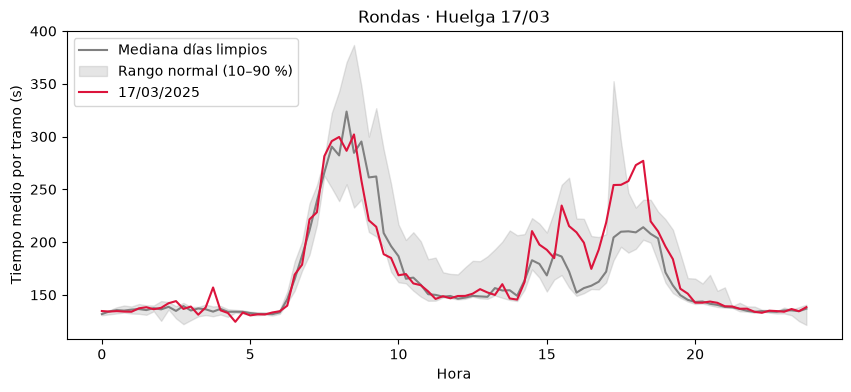

2025-03-17 · Huelga 17/03


franja                                                                             manana  \
corredor                  itin nombre                                                       
-                         66   Ronda de Dalt de Sant Gervasi a Av. Estatut            5.4   
                          69   Ronda de Dalt d'Av. Estatut a Sant Gervasi            -6.0   
                          72   Ronda Litoral de Rambla de Prim a Josep Carner        -0.4   
                          75   Ronda Litoral de Josep Carner a Rambla de Prim         0.3   
Nord (Nus de la Trinitat) 67   Ronda de Dalt d'Av. Estatut a Nus de la Trinitat      39.7   
                          68   Ronda de Dalt de Nus de la Trinitat a Av. Estatut    -18.0   
                          71   Ronda Litoral de Nus de la Trinitat a Rambla de...   -17.6   
                          76   Ronda Litoral de Rambla de Prim a Nus de la Tri...    47.0   
Sud/oest (Llobregat)      65   Ronda de Dalt de Diagonal a Sant Gervasi              -0.5   
                          70   Ronda de Dalt de Sant Gervasi a Diagonal              -3.9   
                          73   Ronda Litoral de Josep Carner a Estació de Can ...    -1.6   
                          74   Ronda Litoral d'Estació de Can Tunis a Josep Ca...   -24.2   

franja                                                                             tarde  
corredor                  itin nombre                                                     
-                         66   Ronda de Dalt de Sant Gervasi a Av. Estatut          23.5  
                          69   Ronda de Dalt d'Av. Estatut a Sant Gervasi           16.0  
                          72   Ronda Litoral de Rambla de Prim a Josep Carner       -4.5  
                          75   Ronda Litoral de Josep Carner a Rambla de Prim       48.1  
Nord (Nus de la Trinitat) 67   Ronda de Dalt d'Av. Estatut a Nus de la Trinitat     32.8  
                          68   Ronda de Dalt de Nus de la Trinitat a Av. Estatut    -8.9  
                          71   Ronda Litoral de Nus de la Trinitat a Rambla de...    5.2  
                          76   Ronda Litoral de Rambla de Prim a Nus de la Tri...   51.4  
Sud/oest (Llobregat)      65   Ronda de Dalt de Diagonal a Sant Gervasi             34.1  
                          70   Ronda de Dalt de Sant Gervasi a Diagonal              5.6  
                          73   Ronda Litoral de Josep Carner a Estació de Can ...    0.0  
                          74   Ronda Litoral d'Estació de Can Tunis a Josep Ca...   18.4

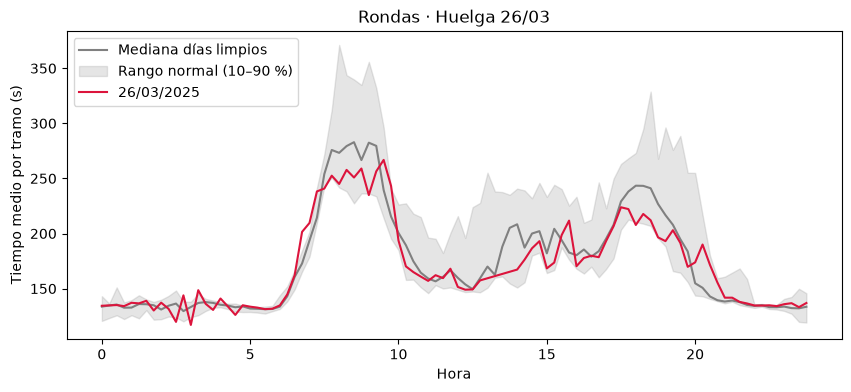

2025-03-26 · Huelga 26/03


franja                                                                             manana  \
corredor                  itin nombre                                                       
-                         66   Ronda de Dalt de Sant Gervasi a Av. Estatut            0.3   
                          69   Ronda de Dalt d'Av. Estatut a Sant Gervasi           -15.6   
                          72   Ronda Litoral de Rambla de Prim a Josep Carner         6.6   
                          75   Ronda Litoral de Josep Carner a Rambla de Prim         1.2   
Nord (Nus de la Trinitat) 67   Ronda de Dalt d'Av. Estatut a Nus de la Trinitat      -8.9   
                          68   Ronda de Dalt de Nus de la Trinitat a Av. Estatut     -7.7   
                          71   Ronda Litoral de Nus de la Trinitat a Rambla de...    -9.4   
                          76   Ronda Litoral de Rambla de Prim a Nus de la Tri...     1.4   
Sud/oest (Llobregat)      65   Ronda de Dalt de Diagonal a Sant Gervasi              -8.5   
                          70   Ronda de Dalt de Sant Gervasi a Diagonal               6.9   
                          73   Ronda Litoral de Josep Carner a Estació de Can ...     0.7   
                          74   Ronda Litoral d'Estació de Can Tunis a Josep Ca...    -2.3   

franja                                                                             tarde  
corredor                  itin nombre                                                     
-                         66   Ronda de Dalt de Sant Gervasi a Av. Estatut         -10.7  
                          69   Ronda de Dalt d'Av. Estatut a Sant Gervasi            3.1  
                          72   Ronda Litoral de Rambla de Prim a Josep Carner      -11.0  
                          75   Ronda Litoral de Josep Carner a Rambla de Prim       -4.6  
Nord (Nus de la Trinitat) 67   Ronda de Dalt d'Av. Estatut a Nus de la Trinitat    -16.2  
                          68   Ronda de Dalt de Nus de la Trinitat a Av. Estatut     1.3  
                          71   Ronda Litoral de Nus de la Trinitat a Rambla de...    4.6  
                          76   Ronda Litoral de Rambla de Prim a Nus de la Tri...    0.7  
Sud/oest (Llobregat)      65   Ronda de Dalt de Diagonal a Sant Gervasi             -3.6  
                          70   Ronda de Dalt de Sant Gervasi a Diagonal             27.7  
                          73   Ronda Litoral de Josep Carner a Estació de Can ...    0.6  
                          74   Ronda Litoral d'Estació de Can Tunis a Josep Ca...    5.7

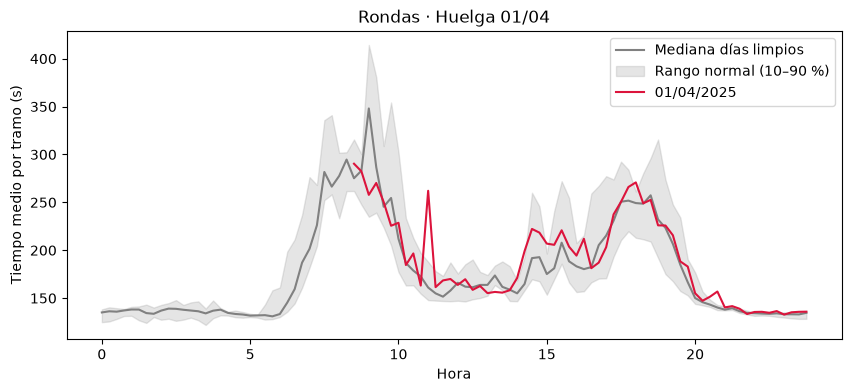

2025-04-01 · Huelga 01/04


franja                                                                             manana  \
corredor                  itin nombre                                                       
-                         66   Ronda de Dalt de Sant Gervasi a Av. Estatut            4.0   
                          69   Ronda de Dalt d'Av. Estatut a Sant Gervasi            -2.0   
                          72   Ronda Litoral de Rambla de Prim a Josep Carner       -11.1   
                          75   Ronda Litoral de Josep Carner a Rambla de Prim         0.3   
Nord (Nus de la Trinitat) 67   Ronda de Dalt d'Av. Estatut a Nus de la Trinitat      -6.8   
                          68   Ronda de Dalt de Nus de la Trinitat a Av. Estatut      4.1   
                          71   Ronda Litoral de Nus de la Trinitat a Rambla de...   -20.3   
                          76   Ronda Litoral de Rambla de Prim a Nus de la Tri...     0.5   
Sud/oest (Llobregat)      65   Ronda de Dalt de Diagonal a Sant Gervasi               4.7   
                          70   Ronda de Dalt de Sant Gervasi a Diagonal               8.5   
                          73   Ronda Litoral de Josep Carner a Estació de Can ...     0.2   
                          74   Ronda Litoral d'Estació de Can Tunis a Josep Ca...    16.5   

franja                                                                             tarde  
corredor                  itin nombre                                                     
-                         66   Ronda de Dalt de Sant Gervasi a Av. Estatut           1.3  
                          69   Ronda de Dalt d'Av. Estatut a Sant Gervasi            7.0  
                          72   Ronda Litoral de Rambla de Prim a Josep Carner       -5.5  
                          75   Ronda Litoral de Josep Carner a Rambla de Prim        1.0  
Nord (Nus de la Trinitat) 67   Ronda de Dalt d'Av. Estatut a Nus de la Trinitat     61.6  
                          68   Ronda de Dalt de Nus de la Trinitat a Av. Estatut    -7.1  
                          71   Ronda Litoral de Nus de la Trinitat a Rambla de...    2.8  
                          76   Ronda Litoral de Rambla de Prim a Nus de la Tri...    2.9  
Sud/oest (Llobregat)      65   Ronda de Dalt de Diagonal a Sant Gervasi            -13.2  
                          70   Ronda de Dalt de Sant Gervasi a Diagonal             -4.9  
                          73   Ronda Litoral de Josep Carner a Estació de Can ...   -1.4  
                          74   Ronda Litoral d'Estació de Can Tunis a Josep Ca...   -2.0

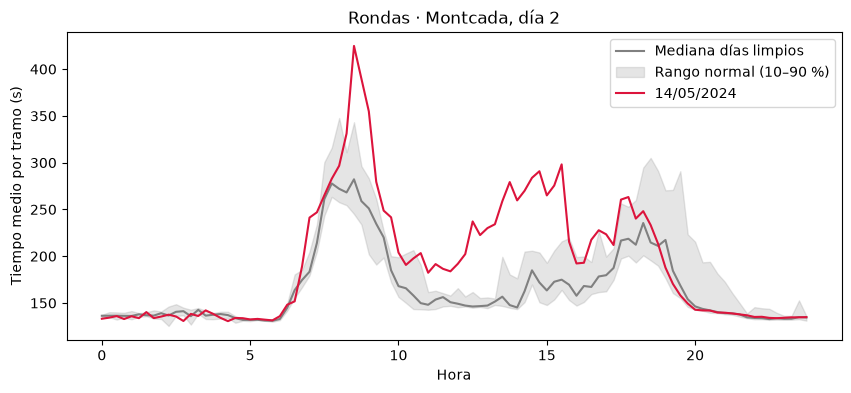

2024-05-14 · Montcada, día 2


franja                                                                             manana  \
corredor                  itin nombre                                                       
-                         66   Ronda de Dalt de Sant Gervasi a Av. Estatut           22.3   
                          69   Ronda de Dalt d'Av. Estatut a Sant Gervasi            30.0   
                          72   Ronda Litoral de Rambla de Prim a Josep Carner        16.4   
                          75   Ronda Litoral de Josep Carner a Rambla de Prim         0.5   
Nord (Nus de la Trinitat) 67   Ronda de Dalt d'Av. Estatut a Nus de la Trinitat      98.0   
                          68   Ronda de Dalt de Nus de la Trinitat a Av. Estatut     38.0   
                          71   Ronda Litoral de Nus de la Trinitat a Rambla de...    42.5   
                          76   Ronda Litoral de Rambla de Prim a Nus de la Tri...   134.6   
Sud/oest (Llobregat)      65   Ronda de Dalt de Diagonal a Sant Gervasi              -7.4   
                          70   Ronda de Dalt de Sant Gervasi a Diagonal              18.3   
                          73   Ronda Litoral de Josep Carner a Estació de Can ...     3.4   
                          74   Ronda Litoral d'Estació de Can Tunis a Josep Ca...     9.9   

franja                                                                             tarde  
corredor                  itin nombre                                                     
-                         66   Ronda de Dalt de Sant Gervasi a Av. Estatut           7.2  
                          69   Ronda de Dalt d'Av. Estatut a Sant Gervasi           -2.0  
                          72   Ronda Litoral de Rambla de Prim a Josep Carner       -6.4  
                          75   Ronda Litoral de Josep Carner a Rambla de Prim        3.1  
Nord (Nus de la Trinitat) 67   Ronda de Dalt d'Av. Estatut a Nus de la Trinitat     51.3  
                          68   Ronda de Dalt de Nus de la Trinitat a Av. Estatut    -4.8  
                          71   Ronda Litoral de Nus de la Trinitat a Rambla de...    1.2  
                          76   Ronda Litoral de Rambla de Prim a Nus de la Tri...    5.0  
Sud/oest (Llobregat)      65   Ronda de Dalt de Diagonal a Sant Gervasi             43.7  
                          70   Ronda de Dalt de Sant Gervasi a Diagonal             -0.8  
                          73   Ronda Litoral de Josep Carner a Estació de Can ...   -1.5  
                          74   Ronda Litoral d'Estació de Can Tunis a Josep Ca...    0.1

In [29]:
def perfil(d, itins, titulo):
    d = pd.Timestamp(d)
    x = tr[tr.itin.isin(itins)].copy()
    x["hm"] = x.ts.dt.hour + x.ts.dt.minute // 15 / 4
    x = x.groupby(["fecha", "hm", "itin"]).t.mean().groupby(["fecha", "hm"]).mean()
    ref_dias = [f for f in limpios if pd.Timestamp(f).day_of_week == d.day_of_week]
    ref_dias = sorted(ref_dias, key=lambda f: abs(pd.Timestamp(f) - d))[:K_REF]
    q = x[x.index.get_level_values("fecha").isin(ref_dias)].groupby("hm").quantile([0.1, 0.5, 0.9]).unstack()
    ax = q[0.5].plot(label="Mediana días limpios", color="grey", figsize=(10, 4))
    ax.fill_between(q.index, q[0.1], q[0.9], color="grey", alpha=0.2, label="Rango normal (10–90 %)")
    if d in x.index.get_level_values("fecha"):
        x.xs(d, level="fecha").plot(ax=ax, label=d.strftime("%d/%m/%Y"), color="crimson")
    ax.set(title=titulo, xlabel="Hora", ylabel="Tiempo medio por tramo (s)"); ax.legend(); plt.show()

def detalle(fecha):
    e = efecto_dia(dia, pd.Timestamp(fecha)).rename("ef").reset_index()
    e["efecto_%"] = (np.expm1(e.ef) * 100).round(1)
    e["nombre"] = e.itin.map(itin.nombre)
    e["corredor"] = e.itin.map(itin.corredor).fillna("-")
    print(fecha, "·", TODOS_DIAS.get(fecha, ""))
    display(e.pivot_table(index=["corredor", "itin", "nombre"], columns="franja", values="efecto_%"))

for d, nombre in TODOS_DIAS.items():
    if pd.Timestamp(d) in set(tr.fecha):
        perfil(d, RONDAS, f"Rondas · {nombre}")
        detalle(d)

**Detalle.**
- **13/05/2024:** la mañana está dentro del rango normal. El aumento de la tarde se concentra en los tramos que van a
  Josep Carner (+177 % y +70 %) y en Ronda de Dalt Diagonal–Sant Gervasi (+58 %), sin cambios en el acceso norte:
  es un atasco local, no atribuible a la avería de la R1.
- **17/03/2025:** la mañana es normal y la tarde (17–18:30 h) queda por encima del rango, de forma repartida e incluido el acceso norte.
- **26/03 y 01/04/2025:** dentro del rango normal todo el día.
- **14/05/2024:** pico a las 8:30 h muy por encima del rango normal y congestión anómala de 12 a 15:30 h. El aumento de
  la mañana se concentra en el **acceso norte (Nus de la Trinitat)**: +98 %, +135 %, +43 % y +38 % en sus cuatro tramos.

## 8. Avería de la R1 (13/05/2024): corredor norte frente a sur/oeste (H5)

manana: Nord -11.1 % | Sud/oest +0.2 % | diferencia -11.3 % (p placebo = 0.416)
tarde: Nord +4.0 % | Sud/oest +44.9 % | diferencia -28.2 % (p placebo = 0.027)


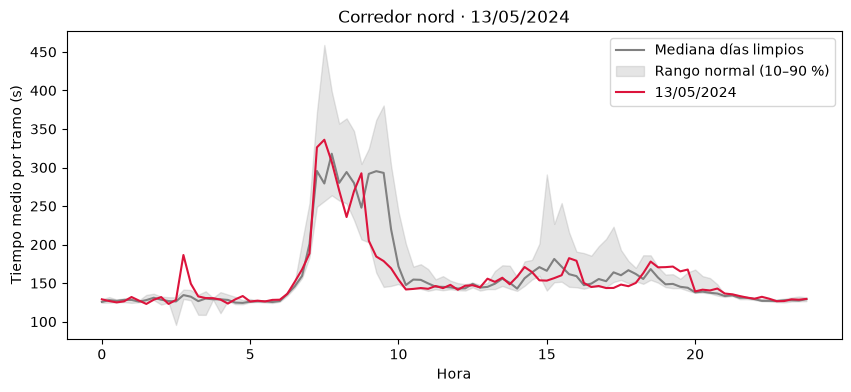

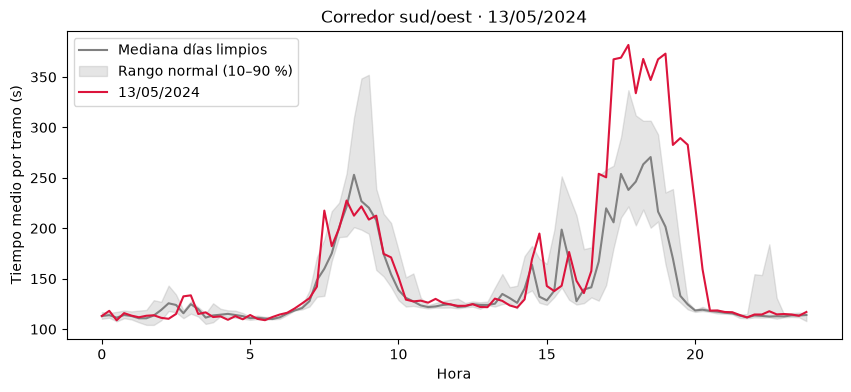

In [30]:
d = pd.Timestamp("2024-05-13")
r = resumen([d], "corredor").set_index(["franja", "grupo"]).ef.unstack()
p = resumen(limpios, "corredor").set_index(["fecha", "franja", "grupo"]).ef.unstack()
N, S = "Nord (Nus de la Trinitat)", "Sud/oest (Llobregat)"
for fr in r.index:
    dif = r.loc[fr, N] - r.loc[fr, S]
    pv = ((p[N] - p[S]).xs(fr, level="franja").abs() >= abs(dif)).mean()
    print(f"{fr}: Nord {np.expm1(r.loc[fr, N])*100:+.1f} % | Sud/oest {np.expm1(r.loc[fr, S])*100:+.1f} % "
          f"| diferencia {np.expm1(dif)*100:+.1f} % (p placebo = {pv:.3f})")
perfil(d, CORREDOR[N], "Corredor nord · 13/05/2024")
perfil(d, CORREDOR[S], "Corredor sud/oest · 13/05/2024")

**Resultado H5.** No se cumple el día de la avería: por la mañana no hay diferencia entre corredores (p = 0,42) y por
la tarde sube más el sur/oeste (+45 % frente a +4 %, p = 0,027), por el atasco de Josep Carner. Pero **el día siguiente
(14/05) sí se observa el patrón esperado**: la congestión de la mañana se concentra en el acceso norte.

**Corte de Montcada (13/05 – 14/06/2024), día a día.** Si los usuarios de la R3/R4/R7 cambiaron al coche, la congestión
de la mañana debería subir en el corredor norte (Nus de la Trinitat) durante el corte y no en el sur/oeste (control).

C:\Users\marti\AppData\Local\Temp\ipykernel_2664\1208576342.py:11: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  tabla["lluvia_manana_mm"] = cal.lluvia_manana_pond.reindex(tabla.index).round(1)
C:\Users\marti\AppData\Local\Temp\ipykernel_2664\1208576342.py:12: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  tabla["mal_tiempo"] = cal.mal_tiempo.reindex(tabla.index)


efecto_%                       \
grupo Nord (Nus de la Trinitat) Sud/oest (Llobregat)   
13/05                     -11.1                  0.2   
14/05                      73.9                  5.6   
15/05                       6.3                  9.0   
16/05                       4.0                  6.7   
17/05                       1.5                -16.2   
21/05                      15.3                  3.4   
22/05                      10.5                 11.5   
23/05                       4.7                 -1.4   
24/05                      13.5                 -0.3   
27/05                      14.7                 10.2   
28/05                      -1.9                 -2.5   
29/05                     -15.4                 11.6   
30/05                       8.8                 10.7   
31/05                       8.2                 -8.3   
03/06                     -20.5                 -3.8   
04/06                      -1.9                  5.9   
05/06                      -3.1                 -7.7   
06/06                      22.6                  0.7   
07/06                       7.1                  7.4   
10/06                      13.4                 -3.0   
11/06                      -3.3                 -0.4   
12/06                       6.2                  4.4   
13/06                      37.6                 21.2   
14/06                      -3.3                  6.3   

                      p_placebo                      lluvia_manana_mm  \
grupo Nord (Nus de la Trinitat) Sud/oest (Llobregat)                    
13/05                     0.383                0.991              0.0   
14/05                     0.000                0.589              4.4   
15/05                     0.617                0.402              1.6   
16/05                     0.738                0.528              0.3   
17/05                     0.893                0.121              0.2   
21/05                     0.290                0.790              0.1   
22/05                     0.453                0.276              0.6   
23/05                     0.715                0.907              0.5   
24/05                     0.336                0.986              0.8   
27/05                     0.294                0.355              0.0   
28/05                     0.855                0.832              0.0   
29/05                     0.220                0.276              0.0   
30/05                     0.509                0.332              0.0   
31/05                     0.551                0.397              0.8   
03/06                     0.117                0.738              0.0   
04/06                     0.864                0.561              0.0   
05/06                     0.766                0.435              0.0   
06/06                     0.136                0.967              0.0   
07/06                     0.603                0.472              0.0   
10/06                     0.336                0.804              2.1   
11/06                     0.752                0.972              1.6   
12/06                     0.617                0.720              0.2   
13/06                     0.028                0.098              0.0   
14/06                     0.757                0.551              0.2   

      mal_tiempo  
grupo             
13/05      False  
14/05       True  
15/05       True  
16/05       True  
17/05      False  
21/05       True  
22/05       True  
23/05       True  
24/05       True  
27/05      False  
28/05      False  
29/05      False  
30/05      False  
31/05       True  
03/06      False  
04/06      False  
05/06      False  
06/06      False  
07/06      False  
10/06       True  
11/06       True  
12/06       True  
13/06      False  
14/06      False

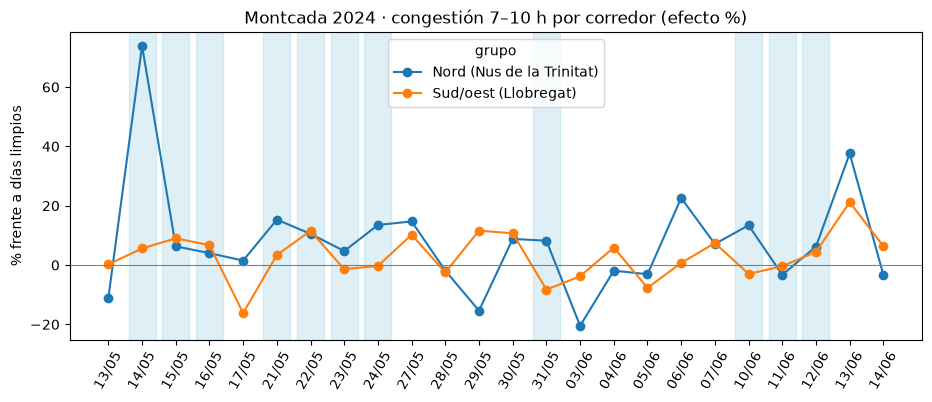

Días 3+ sin mal tiempo (12 días): Nord +2.8 % | Sud/oest +3.2 % | diferencia -0.4 % (p placebo = 0.933)


In [35]:
INICIO_M, FIN_M = "2024-05-13", "2024-06-14"
lab_m = cal.loc[INICIO_M:FIN_M]
lab_m = lab_m[(lab_m.dow < 5) & ~lab_m.festivo & ~lab_m.puente & ~lab_m.evento]   # solo se quitan festivos/eventos
dias_m = [d for d in lab_m.index if d in set(dia.fecha)]
plac_c = resumen(limpios, "corredor")
es = resumen(dias_m, "corredor")
es["efecto_%"] = (np.expm1(es.ef) * 100).round(1)
es["p_placebo"] = es.apply(lambda r: (plac_c[(plac_c.grupo == r.grupo) & (plac_c.franja == r.franja)].ef.abs()
                                      >= abs(r.ef)).mean(), axis=1).round(3)
tabla = es[es.franja == "manana"].pivot_table(index="fecha", columns="grupo", values=["efecto_%", "p_placebo"])
tabla["lluvia_manana_mm"] = cal.lluvia_manana_pond.reindex(tabla.index).round(1)
tabla["mal_tiempo"] = cal.mal_tiempo.reindex(tabla.index)
tabla.index = [f"{d:%d/%m}" for d in tabla.index]
display(tabla)
ax = tabla["efecto_%"].plot(marker="o", figsize=(11, 4), title="Montcada 2024 · congestión 7–10 h por corredor (efecto %)")
for i, mt in enumerate(tabla.mal_tiempo):
    if mt: ax.axvspan(i - 0.4, i + 0.4, color="lightblue", alpha=0.4)
ax.axhline(0, color="grey", lw=0.8); ax.set_ylabel("% frente a días limpios")
ax.set_xticks(range(len(tabla))); ax.set_xticklabels(tabla.index, rotation=60); plt.show()

# Prueba conjunta del día 3 en adelante, solo días sin mal tiempo
ok = es[(es.franja == "manana") & (es.fecha > pd.Timestamp("2024-05-14"))]
ok = ok[~ok.fecha.map(cal.mal_tiempo)]
m = ok.pivot(index="fecha", columns="grupo", values="ef")
dif = (m[N] - m[S]).mean()
pc = plac_c[plac_c.franja == "manana"].pivot(index="fecha", columns="grupo", values="ef")
sims = rng.choice((pc[N] - pc[S]).dropna().values, (10_000, len(m))).mean(axis=1)
print(f"Días 3+ sin mal tiempo ({len(m)} días): Nord {np.expm1(m[N].mean())*100:+.1f} % | "
      f"Sud/oest {np.expm1(m[S].mean())*100:+.1f} % | diferencia {np.expm1(dif)*100:+.1f} % "
      f"(p placebo = {(np.abs(sims) >= abs(dif)).mean():.3f})")

**Resultado H6 (corte de Montcada, día a día).** Solo el **día 2 (14/05)** muestra un aumento fuerte y específico del
acceso norte (+74 %, p < 0,001; sur/oeste +6 %). Del día 3 en adelante la congestión vuelve a la normalidad y los dos
corredores se mueven juntos (ver prueba conjunta). El 20/05 (festivo local) se excluye.

Interpretación (hipótesis): el día 2 es un día de transición. Al confirmarse que el corte continúa, muchos usuarios
de la R3/R4/R7 prueban el coche a la vez. Después encuentran otras alternativas (bus de sustitución, otras líneas,
teletrabajo) y el tráfico se normaliza. La recuperación de los viajes que se ve en M2 no se explica por un paso
masivo y permanente al coche.

In [34]:
cols = ["festivo", "puente", "evento", "evento_nombre", "mal_tiempo", "lluvia_pond", "lluvia_manana_pond", "racha_pond", "lluvia_bcn"]
display(cal.loc["2024-05-13":"2024-06-14", cols][cal.loc["2024-05-13":"2024-06-14"].dow < 5].round(1))

,festivo,puente,evento,evento_nombre,mal_tiempo,lluvia_pond,lluvia_manana_pond,racha_pond,lluvia_bcn
2024-05-13,False,False,False,,False,0.0,0.0,35.5,0.0
2024-05-14,False,False,False,,True,11.8,4.4,38.6,10.0
2024-05-15,False,False,False,,True,6.3,1.6,37.5,9.1
2024-05-16,False,False,False,,True,2.4,0.3,36.8,2.9
2024-05-17,False,False,False,,False,1.0,0.2,32.0,1.7
2024-05-20,True,False,False,,False,0.7,0.0,36.1,0.1
2024-05-21,False,False,False,,True,3.3,0.1,37.5,1.1
2024-05-22,False,False,False,,True,8.5,0.6,37.1,6.6
2024-05-23,False,False,False,,True,1.0,0.5,33.1,0.0
2024-05-24,False,False,False,,True,1.7,0.8,36.7,1.0


Mañanas con lluvia ≥ 1 mm sin incidencias: 24


grupo,Nord (Nus de la Trinitat),Sud/oest (Llobregat),lluvia_manana_mm
fecha,,,
2024-04-29,14.3,16.1,8.1
2025-05-06,36.7,11.8,5.6
2024-01-19,24.6,18.1,5.5
2024-11-13,45.3,11.9,3.9
2024-10-17,-7.2,-7.3,3.8
2025-05-09,32.5,10.0,3.5
2024-03-08,29.7,11.2,3.4
2024-10-30,1.3,9.6,2.9
2025-03-21,11.1,42.1,2.5


Con lluvia ≥ 3 mm (7 días): mediana Nord +29.7 % | Sud/oest +11.8 %
Días con Nord ≥ +74 %: 1 de 24


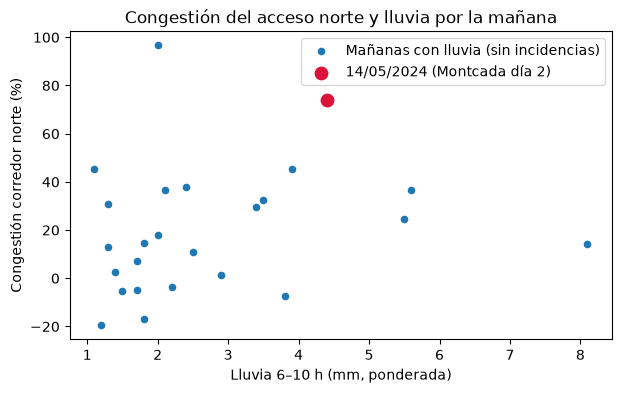

In [36]:
# Laborables con lluvia por la mañana, sin festivos/eventos/verano/Navidad/Semana Santa ni incidencias
excl = set(pd.date_range("2024-05-13", "2024-06-14")) | set(pd.to_datetime(list(TODOS_DIAS)))
ll = cal[(cal.dow < 5) & ~cal.festivo & ~cal.puente & ~cal.evento & ~cal.verano & ~cal.navidad
         & ~cal.semana_santa & (cal.lluvia_manana_pond >= 1) & ~cal.index.isin(excl)]
dias_ll = [d for d in ll.index if d in set(dia.fecha)]
r_ll = resumen(dias_ll, "corredor")
r_ll = r_ll[r_ll.franja == "manana"].pivot(index="fecha", columns="grupo", values="ef")
r_ll = (np.expm1(r_ll) * 100).round(1)
r_ll["lluvia_manana_mm"] = cal.lluvia_manana_pond.reindex(r_ll.index).round(1)

print(f"Mañanas con lluvia ≥ 1 mm sin incidencias: {len(r_ll)}")
display(r_ll.sort_values("lluvia_manana_mm", ascending=False).head(15))
fuertes = r_ll[r_ll.lluvia_manana_mm >= 3]
print(f"Con lluvia ≥ 3 mm ({len(fuertes)} días): mediana Nord {fuertes[N].median():+.1f} % | Sud/oest {fuertes[S].median():+.1f} %")
print(f"Días con Nord ≥ +74 %: {(r_ll[N] >= 73.9).sum()} de {len(r_ll)}")

ax = r_ll.plot.scatter("lluvia_manana_mm", N, figsize=(7, 4), label="Mañanas con lluvia (sin incidencias)")
ax.scatter([4.4], [73.9], color="crimson", s=80, label="14/05/2024 (Montcada día 2)")
ax.set(xlabel="Lluvia 6–10 h (mm, ponderada)", ylabel="Congestión corredor norte (%)",
       title="Congestión del acceso norte y lluvia por la mañana"); ax.legend(); plt.show()

## 9. Relación con Telefónica
En los días limpios, ¿los días con más viajes a Barcelona (M2) tienen más congestión? ¿Y los tipos de día de M2 con más volumen?

Días limpios con las dos fuentes: 227


,manana,tarde,viajes_bcn
manana,1.00,0.19,0.26
tarde,0.19,1.00,0.59
viajes_bcn,0.26,0.59,1.00


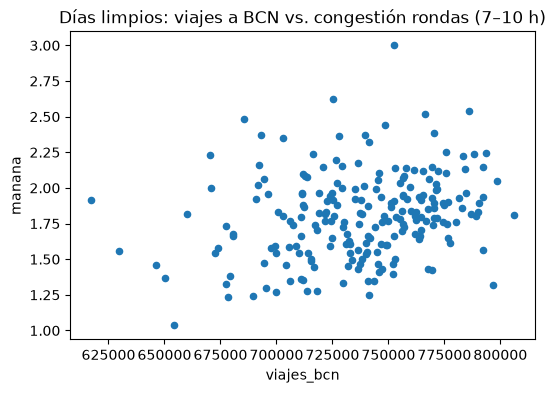

manana        tarde      
     median count median count
tipo                          
A      1.72    52   1.47    53
B      1.74    82   1.57    86
C      1.87    79   1.77    82

In [31]:
m2 = pq.read_table(F_M2, columns=["day", "origen", "municipio_origen", "municipio_destino", "viajes"]).to_pandas()
m2["municipio_origen"] = m2.municipio_origen.astype(str).str.zfill(5)
m2["municipio_destino"] = m2.municipio_destino.astype(str).str.zfill(5)
m2 = m2[(m2.municipio_destino == "08019") & (m2.municipio_origen != "08019") & m2.origen.isin(["Regional", "Residente"])]
vol = m2.groupby(pd.to_datetime(m2.day)).viajes.sum().rename("viajes_bcn")

cong = dia[dia.limpio & (dia.dow < 5)].groupby(["fecha", "franja"]).indice.mean().unstack()
x = cong.join(vol, how="inner")
print("Días limpios con las dos fuentes:", len(x))
display(x.corr(method="spearman").round(2))
x.plot.scatter("viajes_bcn", "manana", figsize=(6, 4), title="Días limpios: viajes a BCN vs. congestión rondas (7–10 h)")
plt.show()

tipos = pd.read_parquet(OUT / "m2_tipos_dia.parquet")
t = tipos["tipo"]; t.index = pd.to_datetime(t.index)
display(cong.join(t, how="inner").groupby("tipo").agg(["median", "count"]).round(2))

**Resultado.** En 227 días limpios, los días con más viajes a Barcelona según Telefónica tienen más congestión en las
rondas (Spearman 0,59 por la tarde y 0,26 por la mañana). El índice también aumenta del tipo de día A al C
(mañana 1,72 → 1,87; tarde 1,47 → 1,77). Las dos fuentes captan la misma demanda.

## 10. Exportar

In [ ]:
dia.to_parquet(OUT / "m4_trafico_diario.parquet")
itin.to_parquet(OUT / "m4_itinerarios.parquet")
real.to_parquet(OUT / "m4_efectos_caos.parquet")
print("Guardado en", OUT)

## 11. Conclusiones
1. **Solo las rondas sirven.** De 78 itinerarios, solo las 12 rondas detectan congestión.
2. **Coherentes con Telefónica:** los días con más viajes a Barcelona hay más congestión (ρ = 0,59 por la tarde),
   y el índice aumenta del tipo de día A al C.
3. **H4: el día de la incidencia no hay más congestión por la mañana** (prueba conjunta de 4 días: −2 % / −4 %, p > 0,5).
   Por la tarde, +9–10 %, no significativo. Las huelgas anunciadas no tienen ningún efecto.
4. **H5 no se cumple:** el 13/05/2024 no se congestiona más el acceso norte; el aumento de la tarde es un atasco local
   en la zona de Josep Carner.
5. **H6 (corte largo de Montcada): no hay paso sostenido al coche.** Del día 3 en adelante, norte y sur se mueven igual
   (diferencia −0,4 %, p = 0,93). El único pico (día 2, +74 % en el norte) coincide con lluvia fuerte; descontando el efecto
   típico de la lluvia, queda ≈ +34 % adicional: un indicio de efecto de transición de un solo día.
6. **Relación con M2:** la «adaptación» que M2 veía durante el corte (los viajes se recuperan) no se explica por un cambio
   permanente al coche. Los usuarios encontraron otras alternativas (bus de sustitución, otras líneas, teletrabajo).

**Limitaciones:** mide el tiempo de recorrido, no el número de coches; el ruido diario es alto (±20–40 %); la lluvia
confunde el resultado del 14/05; solo hay una incidencia larga con datos (faltan los datos de tráfico de abr–oct 2023, Gavà).